Implement decision tree classifiers with hyperparameter tuning, pruning strategies, and interpretability visualization using decision paths to optimize predictive performance and model transparency.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 350

In [4]:
age = np.random.normal(52, 12, n_samples).clip(20, 80)
refill_delay_days = np.random.poisson(lam=6, size=n_samples)
copay_amount = np.random.uniform(5, 75, n_samples)
active_prescriptions = np.random.poisson(lam=3, size=n_samples).clip(1, 10)

In [5]:
adherence_logits = (
    (refill_delay_days < 5).astype(int) * 2.5 
    - (copay_amount > 40).astype(int) * 1.8 
    - (age > 65).astype(int) * 0.8
    + (active_prescriptions < 4).astype(int) * 1.2
)

In [6]:
probs = 1 / (1 + np.exp(-adherence_logits))
target = (probs > np.median(probs)).astype(int)

In [7]:
df_tree = pd.DataFrame({
    'age': age.round(1),
    'refill_delay_days': refill_delay_days,
    'copay_amount': copay_amount.round(2),
    'active_prescriptions': active_prescriptions,
    'adherent': target
})

In [8]:
print("Dataset Class Distribution:")
print(df_tree['adherent'].value_counts())

Dataset Class Distribution:
adherent
0    190
1    160
Name: count, dtype: int64


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

In [10]:
X = df_tree[['age', 'refill_delay_days', 'copay_amount', 'active_prescriptions']]
y = df_tree['adherent']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [12]:
unpruned_tree = DecisionTreeClassifier(random_state=42)
unpruned_tree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [13]:
path = unpruned_tree.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]

In [14]:
pruned_trees = []
for ccp_alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, ccp_alpha=ccp_alpha)
    tree.fit(X_train, y_train)
    pruned_trees.append(tree)

In [15]:
test_scores = [f1_score(y_test, tree.predict(X_test)) for tree in pruned_trees]
best_alpha_idx = np.argmax(test_scores)
best_pruned_tree = pruned_trees[best_alpha_idx]

In [16]:
print(f"Unpruned Tree - Test F1-Score: {f1_score(y_test, unpruned_tree.predict(X_test)):.4f} (Max Depth: {unpruned_tree.get_depth()})")
print(f"Pruned Tree   - Test F1-Score: {f1_score(y_test, best_pruned_tree.predict(X_test)):.4f} (Max Depth: {best_pruned_tree.get_depth()})")

Unpruned Tree - Test F1-Score: 0.9750 (Max Depth: 4)
Pruned Tree   - Test F1-Score: 0.9750 (Max Depth: 4)


In [17]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

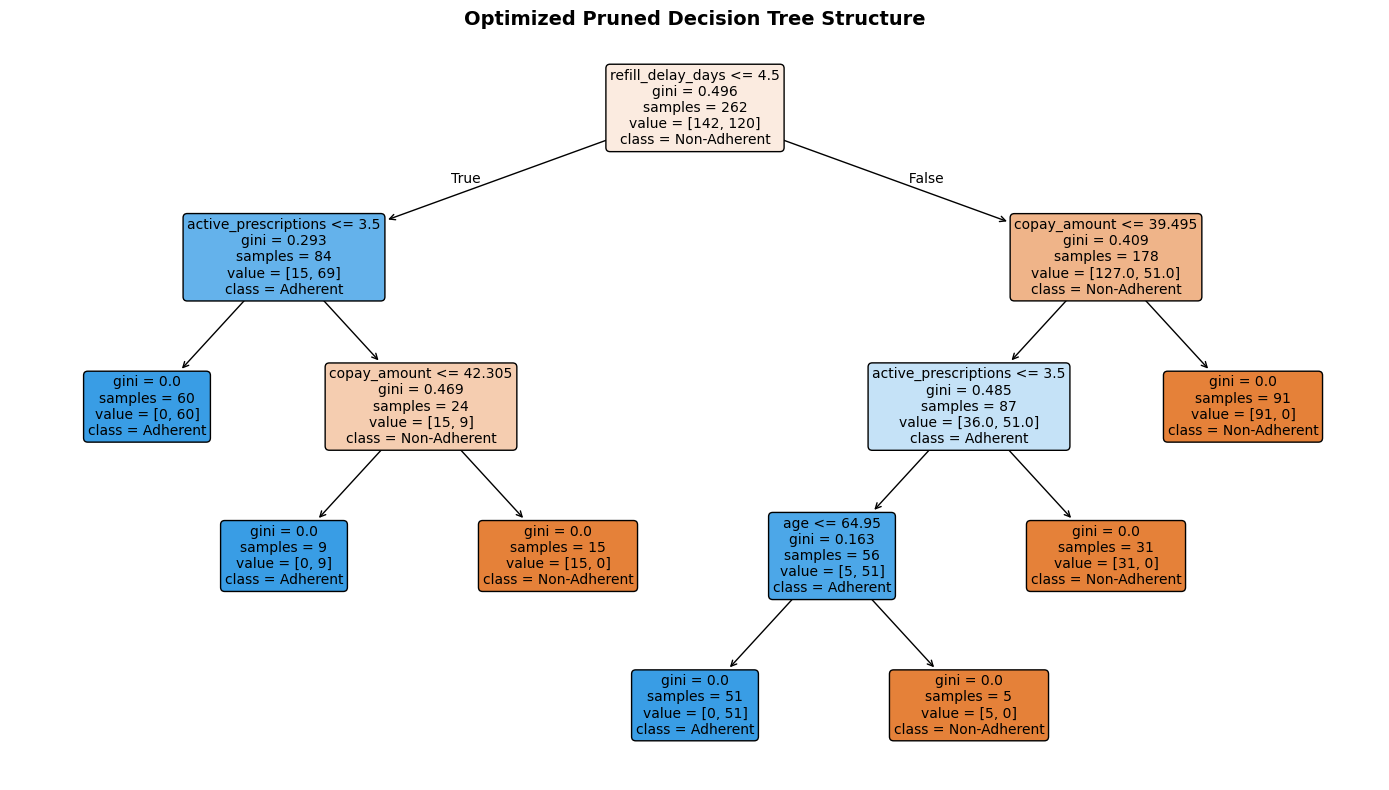

In [18]:
plt.figure(figsize=(14, 8))
plot_tree(
    best_pruned_tree,
    feature_names=X.columns.tolist(),
    class_names=['Non-Adherent', 'Adherent'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Optimized Pruned Decision Tree Structure", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [19]:
sample_idx = 0
sample_patient = X_test.iloc[[sample_idx]]
sample_actual = y_test.iloc[sample_idx]
sample_pred = best_pruned_tree.predict(sample_patient)[0]

In [20]:
node_indicator = best_pruned_tree.decision_path(sample_patient)
leaf_id = best_pruned_tree.apply(sample_patient)[0]

In [21]:
feature = best_pruned_tree.tree_.feature
threshold = best_pruned_tree.tree_.threshold
node_index = node_indicator.indices

In [22]:
print(f"--- Decision Path Trace for Sample Patient {sample_idx} ---")
print(f"Actual Adherence: {sample_actual} | Predicted: {sample_pred}\n")

--- Decision Path Trace for Sample Patient 0 ---
Actual Adherence: 0 | Predicted: 0



In [23]:
for node_id in node_index:
    if leaf_id == node_id:
        print(f"--> Leaf Node {node_id}: Final Prediction = Class {sample_pred}")
        continue

    feature_name = X.columns[feature[node_id]]
    patient_val = sample_patient[feature_name].values[0]
    thresh_val = threshold[node_id]
    
    inequality = "<=" if patient_val <= thresh_val else ">"
    print(f"Node {node_id}: [Feature: {feature_name} = {patient_val:.2f}] {inequality} Threshold {thresh_val:.2f}")

Node 0: [Feature: refill_delay_days = 5.00] > Threshold 4.50
Node 6: [Feature: copay_amount = 28.25] <= Threshold 39.50
Node 7: [Feature: active_prescriptions = 5.00] > Threshold 3.50
--> Leaf Node 11: Final Prediction = Class 0
